# Synthesizing a Precision-Sorted Reading List

##**Demo 2:** (Breadth → **Synthesis** → Discovery)

### Overview
A systematic review normally requires a research team to spend weeks screening PubMed, extracting effect sizes by hand, and building a forest plot in a spreadsheet. This notebook builds that same evidence table from a handful of API calls.

In this demo exercise, you'll zoom in on one well-evidenced relationship in the *diabetic retinopathy* landscape (its connection to *glycated hemoglobin*) and take it from concept to publication-ready evidence synthesis list.

## 0. Setup & Auth

As noted in Demo 1, everything below runs on one API key and one auth header, reused for every call in this notebook. Simply drop in your beta key and you're set up for the rest of the walkthrough.

You're also defining three small helpers here that you'll see reused throughout: `get_json` for a single request, `paginate_all` for walking through multi-page results, and `find_exact_concept` for handling a quirk in how concept search ranks results (more on that in Section 1).

In [ ]:
import time
import urllib.parse

import pandas as pd
import matplotlib.pyplot as plt
import requests

API_KEY = "YOUR_API_KEY"  # replace with your beta API key
BASE_URL = "https://public-api.system.com"
HEADERS = {"x-api-key": API_KEY}


def get_json(path, params=None):
    """GET a Public Graph endpoint and return the parsed JSON body."""
    resp = requests.get(f"{BASE_URL}{path}", headers=HEADERS, params=params or {})
    resp.raise_for_status()
    return resp.json()


def paginate_all(path, params=None, page_size=100, sleep_s=0.0):
    """Walk a paginated list endpoint (offset/limit) and return every record."""
    params = dict(params or {})
    params["limit"] = page_size
    params["include_total"] = True
    offset = 0
    records = []
    total = None
    while total is None or offset < total:
        params["offset"] = offset
        page = get_json(path, params)
        records.extend(page["data"])
        total = page.get("total", len(records))
        offset += page_size
        if sleep_s:
            time.sleep(sleep_s)
        if not page["data"]:
            break
    return records


def find_exact_concept(label, page_size=50, max_records=500):
    """Search concepts by label and return the one whose wikidata_label matches exactly.

    The canonical concept isn't always the top search hit — subtypes and aliases (e.g.
    'background diabetic retinopathy') can outrank it. We page through search results looking
    for an exact (case-insensitive) label match instead of trusting the first few hits.
    """
    hits = paginate_all(
        "/v1/concepts", {"search": f"wikidata_label:{label}"},
        page_size=page_size, sleep_s=0,
    )[:max_records]
    exact = [c for c in hits if c["wikidata_label"].strip().lower() == label.strip().lower()]
    if not exact:
        seen = "\n".join(f"  {c['system_id']} - {c['wikidata_label']}" for c in hits[:20])
        raise ValueError(
            f"No concept with the exact label '{label}' turned up in the first {len(hits)} "
            f"search hits.\nClosest matches seen:\n{seen}\n"
            "Try raising max_records, or pick the right system_id manually from the list above."
        )
    return exact[0]

## 1. Finding the concept

Every variable in the graph that's been grounded to Wikidata rolls up to a `Concept`. Think of it as the canonical, disambiguated version of a topic. You'll start by finding the concept for **diabetic retinopathy**, as that's the anchor everything else in this notebook builds from.

**Note:** The concept search doesn't always rank the canonical concept first. Searching for "diabetic retinopathy" can turn up subtypes like "acute diabetic retinopathy," "childhood diabetic retinopathy," or "nocturnal diabetic retinopathy" ahead of plain "diabetic retinopathy" itself, so you can't just grab the first result (or even the first handful) and trust it's the one you want. To account for this, use `find_exact_concept()` (from Setup) to page through results until it lands on an exact match.

In [ ]:
# Quick look at what the search actually returns — note the subtypes/aliases mixed in
concept_hits = get_json("/v1/concepts", {"search": "wikidata_label:diabetic retinopathy", "limit": 10})
for c in concept_hits["data"]:
    print(c["system_id"], "-", c["wikidata_label"], "-", c["wikidata_id"])

# Page through until we find the exact "diabetic retinopathy" concept
dr_concept = find_exact_concept("diabetic retinopathy")
dr_concept

uxMIuPXV-Y - severe nonproliferative diabetic retinopathy - Q18558039
e9hQFPHL4a - proliferative diabetic retinopathy - Q18967481
RSv0cMiNvS - background diabetic retinopathy - Q18554467
O0vVvNvNdN - diabetic retinopathy - Q631361


{'system_id': 'O0vVvNvNdN',
 'wikidata_label': 'diabetic retinopathy',
 'wikidata_id': 'Q631361',
 'wikidata_description': 'human disease',
 'wikidata_aliases': ['diabetic eye disease',
  'retinal abnormality - diabetes-related',
  'diabetes mellitus insulin dependent type, not stated as uncontrolled, with ophthalmic manifestations',
  'diabetes mellitus juvenile type, not stated as uncontrolled, with ophthalmic manifestations',
  'diabetes mellitus type I [insulin dependent type] [IDDM] [juvenile type], not stated as uncontrolled, with ophthalmic manifestations',
  'diabetic oculopathy']}

## 2. Surveying the evidence landscape

Before zooming into one relationship, you can see which connections to diabetic retinopathy have the *most* supporting literature. Sorting by `num_studies` surfaces the best-evidenced relationships first.

In [ ]:
dr_relationships = get_json(
    f"/v1/concepts/{dr_concept['system_id']}/relationships",
    {"sort": "num_studies:desc", "limit": 20, "include_total": True},
)

# Drop self-relationships. The graph excludes self-relationships; this guard is a safety check only.
dr_relationships["data"] = [
    r for r in dr_relationships["data"]
    if r["source_concept"]["system_id"] != r["target_concept"]["system_id"]
]

landscape_df = pd.DataFrame([
    {
        "relationship_id": r["relationship_id"],
        "source": r["source_concept"]["wikidata_label"],
        "target": r["target_concept"]["wikidata_label"],
        "num_studies": r["num_studies"],
        "num_findings": r["num_findings"],
        "last_published_date": r["last_published_date"],
    }
    for r in dr_relationships["data"]
])
landscape_df

,relationship_id,source,target,num_studies,num_findings,last_published_date
0,DQbECFISI6|O0vVvNvNdN,diabetes,diabetic retinopathy,138,192,2024-11-16T00:00:00
1,q_H3_5POpo|O0vVvNvNdN,glycated hemoglobin,diabetic retinopathy,65,89,2025-05-13T00:00:00
2,uWNNlnauQq|O0vVvNvNdN,blood pressure,diabetic retinopathy,45,73,2024-04-24T00:00:00
3,2RzIlqCjcm|O0vVvNvNdN,insulin,diabetic retinopathy,40,53,2026-02-01T00:00:00
4,JBuGcElHTV|O0vVvNvNdN,HBA1,diabetic retinopathy,36,48,2024-01-01T00:00:00
5,YtQ5lW8obL|O0vVvNvNdN,body mass index,diabetic retinopathy,35,52,2024-03-01T00:00:00
6,wWbfsY5E0d|O0vVvNvNdN,gender,diabetic retinopathy,28,35,2023-03-28T00:00:00
7,YesxPOHDXm|O0vVvNvNdN,blood glucose,diabetic retinopathy,25,36,2025-01-01T00:00:00
8,m70jNJv_Hw|O0vVvNvNdN,hemoglobin,diabetic retinopathy,23,29,2025-01-01T00:00:00
9,uboWgSu-kS|O0vVvNvNdN,systolic blood pressure,diabetic retinopathy,22,25,2023-08-10T00:00:00


## 3. Zooming in

As a way to dive in more deeply, select the second result from the landscape above: the relationship that **diabetic retinopathy** has with **glycated hemoglobin**. `GET /v1/relationships/{relationship_id}` gives a snapshot for meta-analysis: total findings, total studies, and recency.

**Note**: The `relationship_id` is `concept|concept`, and the pipe has to be URL-encoded as `%7C` in the path, which `urllib.parse.quote` handles automatically.

In [ ]:
CANDIDATE_MATCH = "glycated hemoglobin"  # change this to zoom into a different connection

target_row = landscape_df[
    landscape_df["target"].str.contains(CANDIDATE_MATCH, case=False)
    | landscape_df["source"].str.contains(CANDIDATE_MATCH, case=False)
].iloc[0]
relationship_id = target_row["relationship_id"]

encoded_id = urllib.parse.quote(relationship_id)
relationship = get_json(f"/v1/relationships/{encoded_id}")

print("Relationship:", relationship["source_concept"]["wikidata_label"],
      "\u2192", relationship["target_concept"]["wikidata_label"])
print("Supporting studies:", relationship["num_studies"])
print("Individual findings:", relationship["num_findings"])
print("Most recent supporting study:", relationship["last_published_date"])

Relationship: glycated hemoglobin → diabetic retinopathy
Supporting studies: 65
Individual findings: 89
Most recent supporting study: 2025-05-13T00:00:00


## 4. Pulling all underlying findings

Underneath the aggregated view, `Relationships` summarize the evidence; `Associations` are the individual findings that make it up, each with its own statistic, confidence interval, and p-value straight from the source study. You'll pull all of them for this relationship, paging through as needed since list endpoints only return 10 records at a time by default.

In [ ]:
associations = paginate_all(f"/v1/relationships/{encoded_id}/associations")
assoc_df = pd.DataFrame(associations)
print(f"Pulled {len(assoc_df)} individual associations")
assoc_df.head()

Pulled 89 individual associations


,system_id,variable_1_id,variable_2_id,variable_1_wikidata_id,variable_2_wikidata_id,variable_1_concept_id,variable_2_concept_id,variable_1_name,variable_2_name,study_id,statistic_type,statistic_value,ci_upper,ci_lower,ci_level,pubmed_id,system_statistic_type,p_value
0,agXoivVu9w,7FFH-aRJmz,7b_xJoGDJv,Q311213,Q631361,q_H3_5POpo,O0vVvNvNdN,mean level of glycated haemoglobin (HbA),preproliferative diabetic retinopathy or worse,CV1sZxqDWj,odds_ratio,3.290,10.96,0.99,0.0,31462492,odds_ratio,NaN
1,pellDjeoJN,1x3gs62BoK,u9x269MZRV,Q311213,Q631361,q_H3_5POpo,O0vVvNvNdN,glycated hemoglobinA1c,prevalence of diabetic retinopathy,mwwx0JQADL,odds_ratio,1.269,NaN,NaN,NaN,36194621,odds_ratio,NaN
2,ZE6x-VqFqZ,Pj7_SkVhA2,jPOtzuQMJb,Q311213,Q631361,q_H3_5POpo,O0vVvNvNdN,glycated hemoglobin,presence of Diabetic retinopathy,aSPQyRuC-H,odds_ratio,1.210,1.46,1.01,0.0,15785833,odds_ratio,0.047
3,cTMXQcV3s3,h9p7F--MJj,_8Itf85QT4,Q311213,Q631361,q_H3_5POpo,O0vVvNvNdN,glycated hemoglobin (HbA1c),onset of diabetic retinopathy in T2DM,1_ZvhH_Xoe,odds_ratio,0.372,NaN,NaN,NaN,36977687,odds_ratio,NaN
4,fgtOBeNI2d,KZNzzIy4kb,LyXa7znp_i,Q311213,Q631361,q_H3_5POpo,O0vVvNvNdN,glycosylated hemoglobin level at baseline,risk of diabetic retinopathy,pCVK7430Qr,relative_risk_ratio,1.300,1.50,1.20,0.0,15878059,relative_risk_ratio,NaN


## 5. Attaching provenance

Every association you just pulled carries a `study_id`, which is your link to its provenance. Now, pull the matching `Studies` records and join them in, adding the population studied, the study design, the DOI, and the PubMed ID. Once this join is done, every row in your evidence table traces back to a real and citable publication.

In [ ]:
studies = paginate_all(f"/v1/relationships/{encoded_id}/studies")
study_df = pd.DataFrame(studies)

evidence_df = assoc_df.merge(
    study_df, on="study_id", how="left", suffixes=("", "_study")
)
print(f"Evidence table: {len(evidence_df)} findings across {study_df['study_id'].nunique()} studies")
evidence_df.head()

Evidence table: 89 findings across 65 studies


,system_id,variable_1_id,variable_2_id,variable_1_wikidata_id,variable_2_wikidata_id,variable_1_concept_id,variable_2_concept_id,variable_1_name,variable_2_name,study_id,...,ci_upper,ci_lower,ci_level,pubmed_id,system_statistic_type,p_value,doi,pubmed_id_study,population,study_type
0,agXoivVu9w,7FFH-aRJmz,7b_xJoGDJv,Q311213,Q631361,q_H3_5POpo,O0vVvNvNdN,mean level of glycated haemoglobin (HbA),preproliferative diabetic retinopathy or worse,CV1sZxqDWj,...,10.96,0.99,0.0,31462492,odds_ratio,NaN,10.1136/bmj.l4894,31462492,"10,398 children and adults with type 1 diabete...",NaN
1,pellDjeoJN,1x3gs62BoK,u9x269MZRV,Q311213,Q631361,q_H3_5POpo,O0vVvNvNdN,glycated hemoglobinA1c,prevalence of diabetic retinopathy,mwwx0JQADL,...,NaN,NaN,NaN,36194621,odds_ratio,NaN,10.1371/journal.pone.0275617,36194621,7462 Chinese adults with type 2 diabetes melli...,NaN
2,ZE6x-VqFqZ,Pj7_SkVhA2,jPOtzuQMJb,Q311213,Q631361,q_H3_5POpo,O0vVvNvNdN,glycated hemoglobin,presence of Diabetic retinopathy,aSPQyRuC-H,...,1.46,1.01,0.0,15785833,odds_ratio,0.047,10.1590/s0100-879x2005000200010,15785833,210 consecutive and unrelated Brazilian Caucas...,NaN
3,cTMXQcV3s3,h9p7F--MJj,_8Itf85QT4,Q311213,Q631361,q_H3_5POpo,O0vVvNvNdN,glycated hemoglobin (HbA1c),onset of diabetic retinopathy in T2DM,1_ZvhH_Xoe,...,NaN,NaN,NaN,36977687,odds_ratio,NaN,10.1038/s41598-023-31463-5,36977687,T2DM patients with DR and non-DR in an electro...,NaN
4,fgtOBeNI2d,KZNzzIy4kb,LyXa7znp_i,Q311213,Q631361,q_H3_5POpo,O0vVvNvNdN,glycosylated hemoglobin level at baseline,risk of diabetic retinopathy,pCVK7430Qr,...,1.50,1.20,0.0,15878059,relative_risk_ratio,NaN,10.1016/j.ophtha.2004.11.054,15878059,324 participants of the Barbados Eye Studies w...,NaN


## 6. Building the final evidence table

Now, you'll put it all together: one row per finding, most recent first, with the effect size, confidence interval, and p-value sitting right next to the full study provenance (population, design, DOI, PubMed ID). This is the table a systematic review would present as its core result.

**Note:** Not every field shows up for every finding. The API leaves a field out entirely rather than reporting it as blank, so the output only shows what's actually there.

In [ ]:
display_cols = [
    "pubmed_id", "study_type", "population",
    "statistic_type", "statistic_value", "ci_lower", "ci_upper", "p_value", "p_value_equality",
]
available_cols = [c for c in display_cols if c in evidence_df.columns]
missing_cols = [c for c in display_cols if c not in evidence_df.columns]
if missing_cols:
    print(f"Note: not present in this relationship's associations, skipped: {missing_cols}")

final_table = (
    evidence_df[available_cols]
    .sort_values("pubmed_id", ascending=False)
    .reset_index(drop=True)
)
final_table

Note: not present in this relationship's associations, skipped: ['p_value_equality']


,pubmed_id,study_type,population,statistic_type,statistic_value,ci_lower,ci_upper,p_value
0,40361041,NaN,NaN,odds_ratio,1.130,1.050,1.220,NaN
1,39723866,NaN,NaN,mean_difference_standardized,0.500,0.060,0.940,NaN
2,38192497,NaN,Patients diagnosed with type 2 diabetes mellit...,pearson_r,0.342,NaN,NaN,0.001
3,37693352,Experimental Trial,Adults with type 2 diabetes from the 2019 Guan...,odds_ratio,1.325,1.221,1.438,NaN
4,37493689,0,Adults with type 1 diabetes in an prospective ...,adjusted_odds_ratio,1.000,NaN,NaN,0.001
...,...,...,...,...,...,...,...,...
84,15785833,NaN,210 consecutive and unrelated Brazilian Caucas...,odds_ratio,1.210,1.010,1.460,0.047
85,12750094,NaN,410 persons with diabetes mellitus from the Ba...,relative_risk_ratio,6.400,2.500,16.000,NaN
86,11449315,NaN,384 Hong Kong Chinese patients with late-onset...,coefficient,0.170,NaN,NaN,0.050
87,11423515,NaN,"1,441 type 1 diabetic patients enrolled in the...",odds_ratio,1.370,NaN,NaN,0.001


## 7. Visualization as forest plot

For an easier-to-scan format, you can render evidence as a forest plot. Each row is one paper, labeled by its DOI, with a dot marking the reported effect estimate, the horizontal line showing its confidence interval, and the dashed line showing "no effect." Papers are ordered by precision, with the tightest intervals at the top, widening as you move down. From the top, this chart gives you the papers with the most precise results to start with if you're reading the underlying literature yourself.

**Note:** For transparency, a couple of real-data quirks are handled:
* Where a paper reported more than one finding, only its most precise one appears here (we note how many got folded together)
* The x-axis is log-scaled, since effect ratios are naturally distributed that way
* Any confidence interval too wide to fit the chart is truncated at the edge with an arrow and its true value labeled, instead of stretching the whole plot to accommodate one outlier

49 'odds_ratio' findings collapsed to 40 papers (narrowest-CI finding kept per paper); plotting 15.
Saved: /content/forest.pdf  (20,369 bytes)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

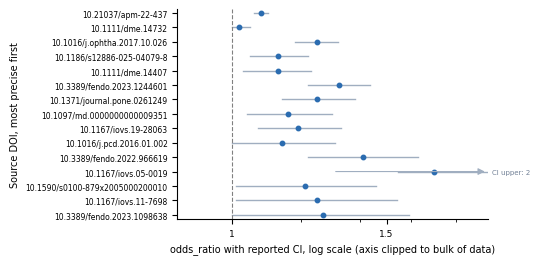

In [ ]:
import os
import matplotlib.pyplot as plt

N_SHOW = 15   # rows in the paper figure (most precise first); None = all papers

dominant_stat = evidence_df["statistic_type"].value_counts().idxmax()
same_stat_df = evidence_df[evidence_df["statistic_type"] == dominant_stat].copy()
same_stat_df["ci_width"] = same_stat_df["ci_upper"] - same_stat_df["ci_lower"]

# Keep only the narrowest-CI (most precise) finding per paper.
plot_df = (
    same_stat_df.sort_values("ci_width")
    .groupby("study_id", as_index=False)
    .first()
    .sort_values("ci_width")
    .reset_index(drop=True)
)
n_papers_total = len(plot_df)
if N_SHOW is not None:
    plot_df = plot_df.head(N_SHOW).reset_index(drop=True)
print(
    f"{len(same_stat_df)} '{dominant_stat}' findings collapsed to "
    f"{n_papers_total} papers (narrowest-CI finding kept per paper); "
    f"plotting {len(plot_df)}."
)

# Show visible axis range from the bulk of the data; out-of-range whiskers get arrows.
is_ratio = "ratio" in dominant_stat.lower()
x_hi = max(plot_df["ci_upper"].quantile(0.95), plot_df["statistic_value"].max() * 1.15)
x_lo = min(plot_df["ci_lower"].clip(lower=1e-6).quantile(0.05), plot_df["statistic_value"].min() * 0.85)
if is_ratio:
    x_lo = max(x_lo, 1e-6)

fig_h = max(2.4, 0.13 * len(plot_df) + 0.8)
fig, ax = plt.subplots(figsize=(5.5, fig_h))
y = range(len(plot_df))

for yi, row in zip(y, plot_df.itertuples()):
    lo = max(row.ci_lower, x_lo)
    hi = min(row.ci_upper, x_hi)

    ax.plot([lo, hi], [yi, yi], color="#a0aec0", linewidth=1.0, zorder=1)
    ax.plot(row.statistic_value, yi, "o", color="#2b6cb0", markersize=3.2, zorder=2)

    if row.ci_lower < x_lo:
        ax.annotate("", xy=(x_lo, yi), xytext=(x_lo * 1.5, yi),
                    arrowprops=dict(arrowstyle="-|>", color="#a0aec0", lw=0.8))
    if row.ci_upper > x_hi:
        ax.annotate("", xy=(x_hi, yi), xytext=(x_hi / 1.5, yi),
                    arrowprops=dict(arrowstyle="-|>", color="#a0aec0", lw=0.8))
        ax.annotate(f"CI upper: {row.ci_upper:.0f}", xy=(x_hi, yi), xytext=(3, 0),
                    textcoords="offset points", fontsize=5, color="#718096", va="center")

if is_ratio:
    from matplotlib.ticker import FixedLocator, FixedFormatter, NullFormatter
    ax.set_xscale("log")
    ticks = [t for t in (0.5, 0.7, 1, 1.5, 2, 3, 5) if x_lo <= t <= x_hi]
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(FixedFormatter([f"{t:g}" for t in ticks]))
    ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlim(x_lo, x_hi)
ax.axvline(1 if is_ratio else 0, linestyle="--", linewidth=0.8, color="gray")
ax.set_yticks(list(y))
ax.set_yticklabels(plot_df["doi"].fillna("(no DOI)"), fontsize=5.5)
ax.tick_params(axis="x", labelsize=6.5)
ax.invert_yaxis()   # most precise study at the top
ax.margins(y=0.02)

scale_note = ", log scale" if is_ratio else ""
ax.set_xlabel(f"{dominant_stat} with reported CI{scale_note} (axis clipped to bulk of data)", fontsize=7)
ax.set_ylabel("Source DOI, most precise first", fontsize=7)

for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)

fig.tight_layout()

out_path = os.path.abspath("forest.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print(f"Saved: {out_path}  ({os.path.getsize(out_path):,} bytes)")

from google.colab import files
files.download(out_path)

plt.show()

## 8. Generating a reading list

For a reading list, System takes the top `PAPER_COUNT` most precise papers from the forest plot, checks each one against Unpaywall for a free, legal full-text copy, and builds a table with a direct PDF link where one exists and a `doi.org` link otherwise (which routes through your institution's access if you have one). The list is saved as `reading_list.csv` to easily enable sharing.

**Note:** ⚠ Be sure to replace `example@email.com` at the top with your email address or it may not return results. Additionally, `PAPER_COUNT` is set to 20 to start. Turn it up or down for a longer or shorter list. Not every paper will have a free copy available.

In [ ]:
UNPAYWALL_EMAIL = "example@email.com"  # Replace with your email address (if it is not replaced data will not return from Unpaywall)
PAPER_COUNT = 15  # how many top (most precise) papers to build a reading list for

top_papers_df = plot_df.head(PAPER_COUNT).copy()

manifest_rows = []
for row in top_papers_df.itertuples():
    doi = row.doi
    if pd.isna(doi):
        manifest_rows.append({
            "doi": None, "title": None, "oa_status": "no DOI available",
            "pdf_url": None, "doi_url": None,
        })
        continue

    doi_url = f"https://doi.org/{doi}"
    title, oa_status, pdf_url = None, "unknown / not OA", None
    try:
        resp = requests.get(
            f"https://api.unpaywall.org/v2/{doi}",
            params={"email": UNPAYWALL_EMAIL}, timeout=10,
        )
        resp.raise_for_status()
        data = resp.json()
        title = data.get("title")
        oa_status = data.get("oa_status") or oa_status
        pdf_url = (data.get("best_oa_location") or {}).get("url_for_pdf")
    except requests.RequestException:
        oa_status = "lookup failed"

    manifest_rows.append({
        "doi": doi, "title": title, "oa_status": oa_status,
        "pdf_url": pdf_url, "doi_url": doi_url,
    })
    time.sleep(0.1)

manifest_df = pd.DataFrame(manifest_rows)
has_pdf = manifest_df["pdf_url"].notna().sum()
print(f"{has_pdf} of {len(manifest_df)} papers have a free, legal full-text PDF available via Unpaywall.")
print("The rest link out to doi.org, which routes through your institution's access if you have one.")

manifest_df.to_csv("reading_list.csv", index=False)
manifest_df

7 of 15 papers have a free, legal full-text PDF available via Unpaywall.
The rest link out to doi.org, which routes through your institution's access if you have one.


,doi,title,oa_status,pdf_url,doi_url
0,10.21037/apm-22-437,Systematic review and meta-analysis of the rel...,gold,https://apm.amegroups.com/article/viewFile/986...,https://doi.org/10.21037/apm-22-437
1,10.1111/dme.14732,The natural history of emerging diabetic retin...,closed,None,https://doi.org/10.1111/dme.14732
2,10.1016/j.ophtha.2017.10.026,Ethnic Differences in the Prevalence and Risk ...,closed,None,https://doi.org/10.1016/j.ophtha.2017.10.026
3,10.1186/s12886-025-04079-8,Inverted U-shaped relationship between HbA1c a...,gold,https://bmcophthalmol.biomedcentral.com/counte...,https://doi.org/10.1186/s12886-025-04079-8
4,10.1111/dme.14407,"The association between carotid disease, arter...",closed,None,https://doi.org/10.1111/dme.14407
5,10.3389/fendo.2023.1244601,Development and evaluation of a risk predictio...,gold,https://www.frontiersin.org/articles/10.3389/f...,https://doi.org/10.3389/fendo.2023.1244601
6,10.1371/journal.pone.0261249,Diabetic retinopathy among type 2 diabetes mel...,gold,None,https://doi.org/10.1371/journal.pone.0261249
7,10.1097/md.0000000000009351,Synergistic interaction between prolonged incr...,gold,None,https://doi.org/10.1097/md.0000000000009351
8,10.1167/iovs.19-28063,Visual Field Loss in Patients With Diabetes in...,gold,https://iovs.arvojournals.org/arvo/content_pub...,https://doi.org/10.1167/iovs.19-28063
9,10.1016/j.pcd.2016.01.002,Risk factors for diabetic retinopathy in peopl...,closed,None,https://doi.org/10.1016/j.pcd.2016.01.002


## 9. Up next

Through these demos, you've built both a systems model for a topic and a fully-sourced evidence table for a relationship between two concepts in a handful of API calls.

The next question worth asking is: what connection *should* exist that nobody's tested yet? Demo 3, **Hypothesis Generation**, explores this.